# Tennessee Project STAR — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [Project STAR (Student/Teacher Achievement Ratio), AER / Stock & Watson teaching version](https://search.r-project.org/CRAN/refmans/AER/help/STAR.html), via the [Rdatasets archive](https://github.com/vincentarelbundock/Rdatasets). Full archive: [Harvard Dataverse](https://doi.org/10.7910/DVN/SIWH9F).

Project STAR was a Tennessee education experiment (1985–1989) in 79 schools. Within each school, kindergarten students and teachers were randomly assigned to one of three class types: **small** (13–17 students), **regular** (22–25 students), or **regular+aide** (regular size with a full-time teaching aide). Students were followed through grade 3; some left, and new students joined in later grades.

Each row is one student. Columns ending in `k`, `1`, `2`, `3` refer to kindergarten, grade 1, grade 2, and grade 3.

| Column(s) | Description |
|---|---|
| `rownames` | Student row identifier |
| `gender`, `ethnicity`, `birth` | Student attributes |
| `stark` … `star3` | Class type in that grade: `small`, `regular`, `regular+aide` (missing if not in the study that year) |
| `readk` … `read3` | Reading scaled score (grade-specific scale) |
| `mathk` … `math3` | Math scaled score (grade-specific scale) |
| `lunchk` … `lunch3` | Free lunch status (`free` / `non-free`) |
| `schoolk` … `school3` | School location: `inner-city`, `suburban`, `rural`, `urban` |
| `degreek` … `degree3` | Teacher's highest degree |
| `ladderk` … `ladder3` | Teacher's career-ladder level |
| `experiencek` … `experience3` | Teacher's years of experience |
| `tethnicityk` … `tethnicity3` | Teacher's ethnicity |
| `systemk` … `system3` | School system (district) ID |
| `schoolidk` … `schoolid3` | School ID |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the data (internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
CSV_PATH = DATA / 'STAR.csv'
URL = 'https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/AER/STAR.csv'

if not CSV_PATH.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    CSV_PATH.write_bytes(r.content)

df = pd.read_csv(CSV_PATH)
print(df.shape)
df.head()

(11598, 48)


,rownames,gender,ethnicity,birth,stark,star1,star2,star3,readk,read1,...,tethnicity2,tethnicity3,systemk,system1,system2,system3,schoolidk,schoolid1,schoolid2,schoolid3
0,1122,female,afam,1979 Q3,NaN,NaN,NaN,regular,NaN,NaN,...,NaN,cauc,NaN,NaN,NaN,22.0,NaN,NaN,NaN,54.0
1,1137,female,cauc,1980 Q1,small,small,small,small,447.0,507.0,...,cauc,cauc,30.0,30.0,30.0,30.0,63.0,63.0,63.0,63.0
2,1143,female,afam,1979 Q4,small,small,regular+aide,regular+aide,450.0,579.0,...,afam,cauc,11.0,11.0,11.0,11.0,20.0,20.0,20.0,20.0
3,1160,male,cauc,1979 Q4,NaN,NaN,NaN,small,NaN,NaN,...,NaN,cauc,NaN,NaN,NaN,6.0,NaN,NaN,NaN,8.0
4,1183,male,afam,1980 Q1,regular+aide,NaN,NaN,NaN,439.0,NaN,...,NaN,NaN,11.0,NaN,NaN,NaN,19.0,NaN,NaN,NaN


In [2]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,11598.0,NaN,NaN,NaN,93914.585618,53588.594738,1122.0,47500.25,93927.5,140307.75,186718.0
gender,11578,2,male,6122,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ethnicity,11453,6,cauc,7193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
birth,11528,21,1980 Q3,2304,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stark,6325,3,regular+aide,2231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star1,6829,3,regular,2584,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star2,6840,3,regular+aide,2495,NaN,NaN,NaN,NaN,NaN,NaN,NaN
star3,6802,3,regular+aide,2543,NaN,NaN,NaN,NaN,NaN,NaN,NaN
readk,5789.0,NaN,NaN,NaN,436.725341,31.706262,315.0,414.0,433.0,453.0,627.0
read1,6396.0,NaN,NaN,NaN,520.784553,55.188498,404.0,478.0,514.0,558.0,651.0


## 2. A first look

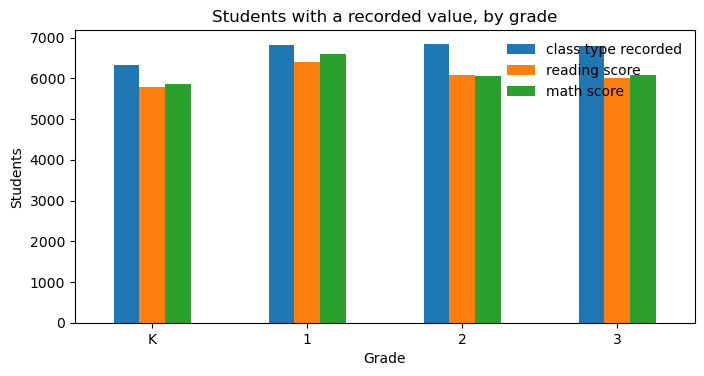

In [3]:
grades = {'K': 'k', '1': '1', '2': '2', '3': '3'}
counts = pd.DataFrame({
    g: {'class type recorded': df['star' + s].notna().sum(),
        'reading score': df['read' + s].notna().sum(),
        'math score': df['math' + s].notna().sum()}
    for g, s in grades.items()
}).T
fig, ax = plt.subplots(figsize=(8, 3.8))
counts.plot.bar(ax=ax, rot=0)
ax.set(xlabel='Grade', ylabel='Students', title='Students with a recorded value, by grade')
ax.legend(frameon=False)
plt.show()

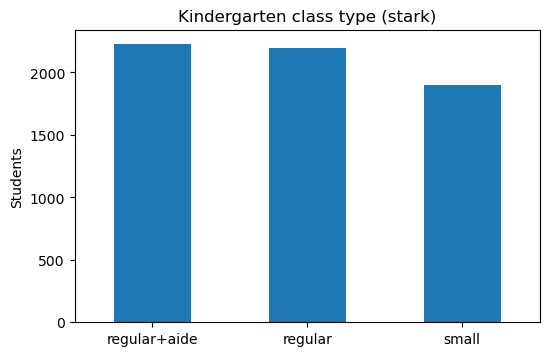

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.8))
df['stark'].value_counts().plot.bar(ax=ax, rot=0)
ax.set(xlabel='', ylabel='Students', title='Kindergarten class type (stark)')
plt.show()

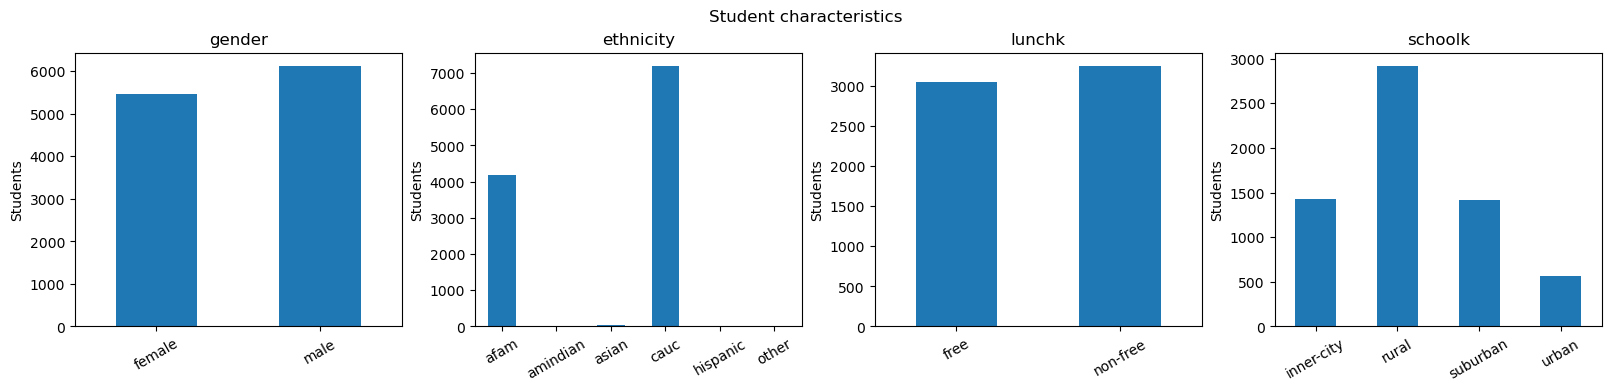

In [5]:
cats = ['gender', 'ethnicity', 'lunchk', 'schoolk']
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
for ax, col in zip(axs, cats):
    df[col].value_counts().sort_index().plot.bar(ax=ax, rot=30)
    ax.set(title=col, xlabel='', ylabel='Students')
fig.suptitle('Student characteristics')
plt.show()

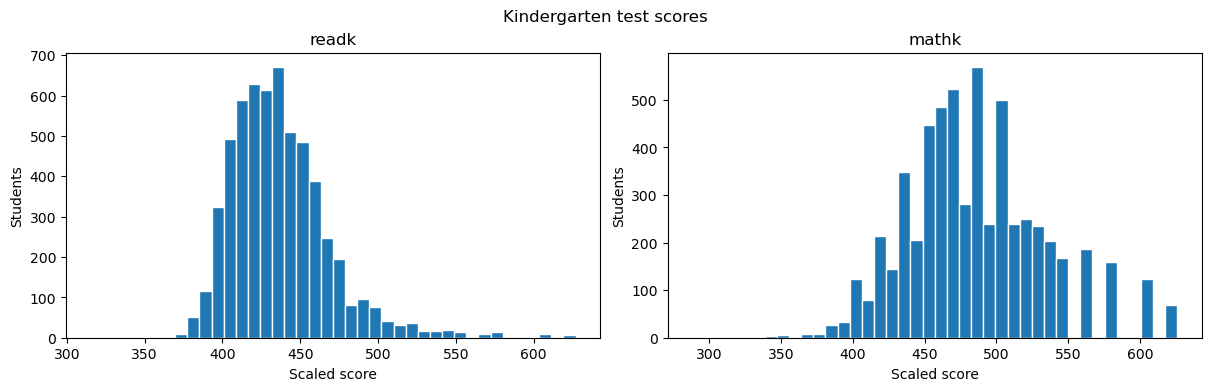

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for ax, col in zip(axs, ['readk', 'mathk']):
    ax.hist(df[col].dropna(), bins=40, edgecolor='white')
    ax.set(xlabel='Scaled score', ylabel='Students', title=col)
fig.suptitle('Kindergarten test scores')
plt.show()

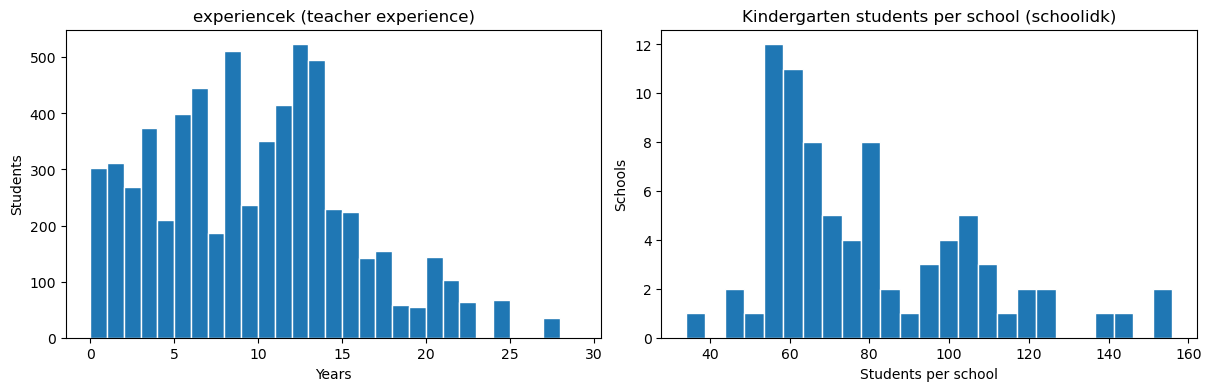

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axs[0].hist(df['experiencek'].dropna(), bins=range(0, 30), edgecolor='white')
axs[0].set(xlabel='Years', ylabel='Students', title='experiencek (teacher experience)')
df.groupby('schoolidk').size().plot.hist(ax=axs[1], bins=25, edgecolor='white')
axs[1].set(xlabel='Students per school', ylabel='Schools', title='Kindergarten students per school (schoolidk)')
plt.show()

## 3. Your exploration
Add your own analysis below.